In [9]:
import pandas as pd
import numpy as np
import os
import re
import matplotlib.pyplot as plt

RAW_PATH = '../02_Data/'
PROCESSED_PATH = '../02_Data/processed'
os.makedirs(PROCESSED_PATH, exist_ok=True)

def clean_price(series):
    return pd.to_numeric(
        series.astype(str).str.replace(r'[\$,€£]', '', regex=True).str.strip() , errors='coerce'
    )

def snapshot(df, name):
    return {
        'dataset' : name,
        'rows' : df.shape[0],
        'cols': df.shape[1],
        'columns': list(df.columns),
        'dtypes': df.dtypes.astype(str).to_dict()
    }

In [10]:
listings_raw = pd.read_csv(os.path.join(RAW_PATH, 'listings.csv'))

# Preserve snapshot of the raw
original_snapshot = snapshot(listings_raw, 'listings_raw')
print("ORIGINAL SNAPSHOT")
for k, v in original_snapshot.items():
    if k not in ('columns', 'dtypes'):
        print(f"  {k}: {v}")

# Working copy for cleaning
listings = listings_raw.copy()
print(f"\n Working copy created: {listings.shape}")

ORIGINAL SNAPSHOT
  dataset: listings_raw
  rows: 15293
  cols: 90

 Working copy created: (15293, 90)


In [11]:
# ID
print(f"Missing IDs: {listings['id'].isnull().sum()}")
print(f"Unique IDs:  {listings['id'].nunique():,}")
print(f"Total rows:  {len(listings):,}")

# Exact duplicate rows
exact_dupes = listings.duplicated().sum()
print(f"Exact duplicate rows: {exact_dupes}")

# --- Prices ---
price_cols = ['price', 'weekly_price', 'monthly_price',
              'security_deposit', 'cleaning_fee', 'extra_people']
for col in price_cols:
    if col in listings.columns:
        listings[col] = clean_price(listings[col])
        print(f"{col} → float  ({listings[col].notna().sum()} valid, {listings[col].isna().sum()} NaN)")

# --- Dates ---
date_cols = ['last_scraped', 'host_since', 'first_review', 'last_review']
for col in date_cols:
    if col in listings.columns:
        listings[col] = pd.to_datetime(listings[col], errors='coerce')

# --- Booleans (t/f strings) ---
bool_cols = ['host_is_superhost', 'host_has_profile_pic',
             'host_identity_verified', 'instant_bookable',
             'is_location_exact', 'requires_license']
for col in bool_cols:
    if col in listings.columns:
        listings[col] = listings[col].map({'t': True, 'f': False})

# --- Percentages ---
pct_cols = ['host_response_rate', 'host_acceptance_rate']
for col in pct_cols:
    if col in listings.columns:
        listings[col] = pd.to_numeric(
            listings[col].astype(str).str.replace('%', '', regex=False),
            errors='coerce'
        )

print("\n Data type standardization complete")


Missing IDs: 0
Unique IDs:  15,293
Total rows:  15,293
Exact duplicate rows: 0
price → float  (13355 valid, 1938 NaN)

 Data type standardization complete


--- Price Distribution (raw cleaned) ---
count    13355.000000
mean       240.616470
std        339.474553
min          3.500000
1%          23.590000
5%          35.411000
25%         89.290000
50%        177.670000
75%        285.500000
95%        548.000000
99%       1815.000000
max      10542.220000
Name: price, dtype: float64

Price <= 0: 0
Price missing: 1938
Price > €1,000: 274
Price > €5,000: 6

minimum_nights < 1: 0
minimum_nights > 30:  5527
minimum_nights > 365: 3

number_of_reviews < 0: 0


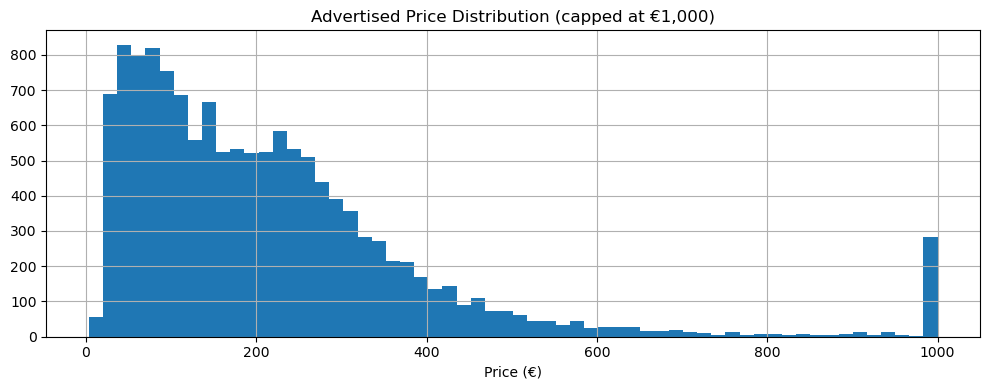

In [12]:
# Price distribution BEFORE any outlier decision
print("--- Price Distribution (raw cleaned) ---")
print(listings['price'].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]))

# Count problem cases
print(f"\nPrice <= 0: {(listings['price'] <= 0).sum()}")
print(f"Price missing: {listings['price'].isna().sum()}")
print(f"Price > €1,000: {(listings['price'] > 1000).sum()}")
print(f"Price > €5,000: {(listings['price'] > 5000).sum()}")

# Minimum nights
print(f"\nminimum_nights < 1: {(listings['minimum_nights'] < 1).sum()}")
print(f"minimum_nights > 30:  {(listings['minimum_nights'] > 30).sum()}")
print(f"minimum_nights > 365: {(listings['minimum_nights'] > 365).sum()}")

# Review counts
print(f"\nnumber_of_reviews < 0: {(listings['number_of_reviews'] < 0).sum()}")

# Visualize price distribution (capped for readability)
listings['price'].dropna().clip(upper=1000).hist(bins=60, figsize=(10, 4))
plt.title('Advertised Price Distribution (capped at €1,000)')
plt.xlabel('Price (€)')
plt.tight_layout()
plt.savefig('../04_Data_Cleaning/price_hist.png', dpi=100)
plt.show()

In [13]:
# Missing summary for key fields
key_fields = ['neighbourhood', 'neighbourhood_cleansed', 'room_type',
              'property_type', 'price', 'host_is_superhost', 'host_since']
for col in key_fields:
    if col in listings.columns:
        pct = (listings[col].isnull().sum() / len(listings)) * 100
        print(f"{col:30s} {pct:5.2f}% missing")

# Standardize text labels
text_cols = ['room_type', 'property_type', 'neighbourhood',
             'neighbourhood_cleansed', 'city', 'country']
for col in text_cols:
    if col in listings.columns:
        listings[col] = (listings[col]
                          .astype(str)
                          .str.strip()
                          .str.replace(r'\s+', ' ', regex=True))

# Standardize neighbourhood capitalization (Title Case)
for col in ['neighbourhood', 'neighbourhood_cleansed']:
    if col in listings.columns:
        listings[col] = listings[col].str.title()


neighbourhood                  100.00% missing
neighbourhood_cleansed          0.00% missing
room_type                       0.00% missing
property_type                   0.00% missing
price                          12.67% missing
host_is_superhost               0.57% missing
host_since                     100.00% missing


In [15]:
import pandas as pd
import numpy as np

RAW = '../02_Data/'
OUT = '../02_Data/processed/'

# ---------- LOAD ----------
listings       = pd.read_csv(RAW + 'listings.csv', low_memory=False)
calendar       = pd.read_csv(RAW + 'calendar.csv', low_memory=False)
reviews        = pd.read_csv(RAW + 'reviews.csv', low_memory=False)
neighbourhoods = pd.read_csv(RAW + 'neighbourhoods.csv', low_memory=False)

# ---------- UNIVERSAL FIX: kill string "nan" everywhere ----------
def kill_nan_strings(df):
    for col in df.columns:
        if df[col].dtype == 'object':
            df[col] = (
                df[col].astype(str).str.strip()
                .replace({'nan': np.nan, 'Nan': np.nan, 'NaN': np.nan,
                          'None': np.nan, 'null': np.nan, '': np.nan})
            )
    return df

for df in [listings, calendar, reviews, neighbourhoods]:
    kill_nan_strings(df)

# ---------- NEIGHBOURHOOD: use the cleansed version ----------
if 'neighbourhood_cleansed' in listings.columns:
    listings['neighbourhood'] = listings['neighbourhood_cleansed']

# ---------- BOOLEANS ----------
for col in ['host_is_superhost', 'host_has_profile_pic', 'host_identity_verified']:
    if col in listings.columns:
        listings[col] = (
            listings[col].astype(str).str.lower()
            .map({'t': True, 'true': True, '1': True,
                  'f': False, 'false': False, '0': False})
            .astype('boolean')
        )
if 'available' in calendar.columns:
    calendar['available'] = (
        calendar['available'].astype(str).str.lower()
        .map({'t': True, 'true': True, 'f': False, 'false': False})
        .astype('boolean')
    )

# ---------- PRICE ----------
def clean_price(s):
    return pd.to_numeric(
        s.astype(str).str.replace(r'[\$,€£]', '', regex=True).str.strip(),
        errors='coerce'
    )
for col in ['price', 'weekly_price', 'monthly_price', 'security_deposit', 'cleaning_fee']:
    if col in listings.columns: listings[col] = clean_price(listings[col])
if 'price' in calendar.columns: calendar['price'] = clean_price(calendar['price'])

# ---------- DATES ----------
for col in ['last_scraped', 'host_since', 'first_review', 'last_review']:
    if col in listings.columns: listings[col] = pd.to_datetime(listings[col], errors='coerce')
calendar['date'] = pd.to_datetime(calendar['date'], errors='coerce')
reviews['date']  = pd.to_datetime(reviews['date'],  errors='coerce')

# ---------- SAVE (with na_rep='' — the critical fix) ----------
listings.to_csv(OUT + 'listings_clean.csv', index=False, na_rep='')
calendar.to_csv(OUT + 'calendar_clean.csv', index=False, na_rep='')
reviews.to_csv(OUT + 'reviews_clean.csv', index=False, na_rep='')
neighbourhoods.to_csv(OUT + 'neighbourhoods_clean.csv', index=False, na_rep='')

# ---------- VERIFY ----------
check = pd.read_csv(OUT + 'listings_clean.csv', low_memory=False)
print(f"listings: {len(check):,} rows")
print(f"neighbourhood non-null: {check['neighbourhood'].notna().sum():,} ({check['neighbourhood'].notna().mean()*100:.1f}%)")
print(f"neighbourhood string 'nan': {(check['neighbourhood'].astype(str).str.lower()=='nan').sum()}")
print(f"price non-null: {check['price'].notna().sum():,}")
print(f"price string 'nan': {(check['price'].astype(str).str.lower()=='nan').sum()}")
print("✅ Done — files rebuilt.")

listings: 15,293 rows
neighbourhood non-null: 15,293 (100.0%)
neighbourhood string 'nan': 0
price non-null: 13,355
price string 'nan': 1938
✅ Done — files rebuilt.


In [16]:
listings.to_csv(os.path.join(PROCESSED_PATH, 'listings_clean.csv'), index=False)
print(f"Saved listings_clean.csv ({listings.shape[0]:,} rows × {listings.shape[1]} cols)")

Saved listings_clean.csv (15,293 rows × 90 cols)


In [17]:
# Load the saved file
check = pd.read_csv('../02_Data/processed/listings_clean.csv', low_memory=False)

print("=" * 60)
print("DIAGNOSIS")
print("=" * 60)

# --- Issue 1: Price ---
print("\n--- PRICE ---")
print(f"  dtype: {check['price'].dtype}")
print(f"  Sample values: {check['price'].head(10).tolist()}")
print(f"  Unique types: {check['price'].apply(type).value_counts().to_dict()}")

# --- Issue 2: Neighbourhood ---
print("\n--- NEIGHBOURHOOD ---")
print(f"  dtype: {check['neighbourhood'].dtype}")
print(f"  Unique values: {check['neighbourhood'].nunique()}")
print(f"  Top 10 values:")
print(check['neighbourhood'].value_counts().head(10))
print(f"\n  Sample: {check['neighbourhood'].head(10).tolist()}")

# --- Check what the EDA notebook sees ---
print("\n--- PRICE SEGMENT (from your EDA) ---")
if 'price_segment' in check.columns:
    print(check['price_segment'].value_counts())
else:
    print("  price_segment column doesn't exist in saved CSV")
    print("  → The EDA notebook is recreating it from 'price'")

DIAGNOSIS

--- PRICE ---
  dtype: float64
  Sample values: [409.0, 388.0, 397.13, 43.24, 226.13, nan, 417.8, 275.5, 107.61, 209.0]
  Unique types: {<class 'float'>: 15293}

--- NEIGHBOURHOOD ---
  dtype: object
  Unique values: 69
  Top 10 values:
neighbourhood
la Dreta de l'Eixample                   2145
el Raval                                 1031
Sant Pere, Santa Caterina i la Ribera     925
la Vila de Gràcia                         924
la Sagrada Família                        910
el Barri Gòtic                            881
l'Antiga Esquerra de l'Eixample           850
Sant Antoni                               846
la Nova Esquerra de l'Eixample            660
el Poble Sec                              650
Name: count, dtype: int64

  Sample: ['la Sagrada Família', 'el Besòs i el Maresme', 'el Barri Gòtic', 'la Barceloneta', "la Dreta de l'Eixample", "el Camp d'en Grassot i Gràcia Nova", 'Vallcarca i els Penitents', "la Dreta de l'Eixample", 'el Raval', 'el Poblenou']

--- PRICE 